In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import matplotlib.pyplot as plt
import jax.numpy as jnp
import equinox as eqx
import time
import optax

from pathlib import Path
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
from jax.lax import scan
from jax import random, jit, vmap, grad

%config InlineBackend.figure_format='retina'

# Burgers equation and the reference solution

We consider the viscous Burgers equation from the pseudospectral notebook,

$$
\frac{\partial u}{\partial t} + u\frac{\partial u}{\partial x} = \nu \frac{\partial^2 u}{\partial x^2}, \quad u(0,t)=u(1,t)=0, \quad u(x,0)=u_0(x), \quad (x, t)\in(0,1)\times(0,T],
$$

with $\nu=0.1$, $T=0.5$, and the initial conditions $u_0$ from the saved dataset.

To measure the error of a PINN we need the reference solution on the whole space-time grid, while the dataset contains only the solution at $t=T$. The cell below contains the pseudospectral solver from the previous notebook (see there for the details), which returns the solution at 63 equispaced times. We add the initial condition as $t=0$, which gives the 64 time levels of the reference implementation.

In [2]:
nu = 0.1
T = 0.5
N_t = 64  # number of time levels, including t = 0

def extend(u):
    # odd extension of the interior values to the periodic grid on [0, 2)
    return jnp.concatenate([jnp.zeros(1), u, jnp.zeros(1), -u[::-1]])

def solve_burgers(u0, nu=0.1, T=0.5, n_out=63, substeps=32):
    """Integrate Burgers from u0 (values at N interior nodes) up to T.

    Returns the solution at `n_out` equispaced times in (0, T], shape (n_out, N).
    """
    N = u0.shape[0]
    M = 2 * (N + 1)
    dt = T / (n_out * substeps)

    m = jnp.arange(M // 2 + 1)  # rfft wavenumber indices
    k = jnp.pi * m
    ik = 1j * k * (m != M // 2)  # zero Nyquist mode for odd derivatives
    mask = m < M / 3  # 2/3 dealiasing rule
    L = -nu * k**2
    E, E2 = jnp.exp(L * dt), jnp.exp(L * dt / 2)

    g = lambda v: -0.5 * ik * mask * jnp.fft.rfft(jnp.fft.irfft(v, n=M)**2)

    def step(v, _):  # integrating factor RK4
        a = g(v)
        b = g(E2 * (v + dt / 2 * a))
        c = g(E2 * v + dt / 2 * b)
        d = g(E * v + dt * E2 * c)
        return E * v + dt / 6 * (E * a + 2 * E2 * (b + c) + d), None

    def output(v, _):
        v, _ = scan(step, v, None, length=substeps)
        return v, jnp.fft.irfft(v, n=M)[1:N+1]

    return scan(output, jnp.fft.rfft(extend(u0)), None, length=n_out)[1]

def solve_reference(u0):
    # solution on the whole space-time grid, shape (N_t, N)
    return jnp.concatenate([u0[None], solve_burgers(u0, nu, T, N_t - 1)])

# Siren

We use the same network as in the elliptic notebook (see there for the motivation) with two inputs, $(x, t)$. This time the network returns the raw output, and the boundary and initial conditions are imposed by the ansatz described below.

*Reference:* V. Sitzmann, J. Martel, A. Bergman, D. Lindell, G. Wetzstein, [Implicit Neural Representations with Periodic Activation Functions](https://arxiv.org/abs/2006.09661), NeurIPS 2020.

In [3]:
class Siren(eqx.Module):
    matrices: list
    biases: list

    def __init__(self, N_features, N_layers, key, s0=10):
        keys = random.split(key, N_layers+1)
        features = [N_features[0],] + [N_features[1],]*(N_layers-1) + [N_features[-1],]
        self.matrices = [random.uniform(key, (f_in, f_out), minval=-1, maxval=1)*jnp.sqrt(6/f_in) for f_in, f_out, key in zip(features[:-1], features[1:], keys)]
        keys = random.split(keys[-1], N_layers)
        self.biases = [jnp.zeros((f_out,)) for f_in, f_out, key in zip(features[:-1], features[1:], keys)]
        self.matrices[0] = self.matrices[0]*s0

    def __call__(self, z):
        f = z @ self.matrices[0] + self.biases[0]
        for i in range(1, len(self.matrices)):
            f = jnp.sin(f)
            f = f @ self.matrices[i] + self.biases[i]
        return f[0]

# PINNs for Burgers equation (residual loss)

The Burgers equation is nonlinear and has no variational (energy) formulation like the one we used for the elliptic problem, so we use the general approach of physics-informed neural networks: we substitute the network $u_\theta(x,t)$ into the equation and minimise the *residual*

$$
r_\theta(x,t) = \frac{\partial u_\theta}{\partial t} + u_\theta\frac{\partial u_\theta}{\partial x} - \nu\frac{\partial^2 u_\theta}{\partial x^2}, \qquad
L(\theta) = \mathbb{E}_{(x,t)}\left[r_\theta(x,t)^2\right] \approx \frac{1}{B}\sum_{i=1}^{B} r_\theta(x_i, t_i)^2,
$$

where the expectation is over the uniform distribution on the space-time domain $(0,1)\times(0,T)$, and the *collocation points* $(x_i,t_i)$ are sampled from it. All the derivatives are computed by automatic differentiation (`grad` in JAX, nested for the second derivative). The loss is zero if and only if the network satisfies the equation. The reference solution is **not** used in training, it is only used to monitor the error.

### Boundary and initial conditions

As in the elliptic notebook, we impose the conditions by the form of the solution, so that the loss contains only the residual:

$$
u_\theta(x,t) = u_0(x) + \sin(\pi x)\,\frac{t}{T}\,\Phi_\theta\left(x, \frac{t}{T}\right),
$$

where $\Phi_\theta$ is the Siren. For any $\theta$ this satisfies $u_\theta(0,t)=u_\theta(1,t)=0$ (since $u_0(0)=u_0(1)=0$) and $u_\theta(x,0)=u_0(x)$. The time is rescaled to $t/T\in[0,1]$ for the input of the network.

The initial condition is known only at the grid nodes, and we need it as a smooth function with derivatives, because $\partial_{xx}u_\theta$ contains $\frac{d^2 u_0}{dx^2}$ (a piecewise linear interpolant would have $\frac{d^2 u_0}{dx^2}=0$ and would silently change the equation). We use the sine series, the same odd extension that was used in the pseudospectral notebook:

$$
u_0(x) = \sum_{m=1}^{N} b_m \sin(m\pi x), \qquad b_m = \frac{2}{N+1}\sum_{j=1}^{N} u_0(x_j)\sin(m\pi x_j),
$$

which reproduces the given values exactly at the nodes.

*Reference:* M. Raissi, P. Perdikaris, G. Karniadakis, Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations, Journal of Computational Physics 378, 2019.

In [4]:
def sine_coefficients(u0):
    # coefficients b_m of the sine series of the initial condition (discrete sine transform)
    return 2 / (N + 1) * jnp.sin(jnp.pi * modes[:, None] * x[None, :]) @ u0

def ansatz(model, b, xt):
    # u(x, t) = u_0(x) + sin(pi x) * t / T * Siren(x, t / T)
    x_, t_ = xt
    u0 = jnp.sum(b * jnp.sin(jnp.pi * modes * x_))
    return u0 + jnp.sin(jnp.pi * x_) * (t_ / T) * model(jnp.array([x_, t_ / T]))

def residual(model, b, xt):
    u = lambda xt: ansatz(model, b, xt)
    du = grad(u)(xt)  # (du/dx, du/dt)
    d2u_dx2 = grad(lambda xt: grad(u)(xt)[0])(xt)[0]
    return du[1] + u(xt) * du[0] - nu * d2u_dx2

def compute_loss(model, b, xt):
    # xt has shape (B, 2), the columns are x and t
    return jnp.mean(vmap(lambda p: residual(model, b, p))(xt)**2)

compute_loss_and_grads = eqx.filter_value_and_grad(compute_loss)

# Training with SGD

The training is organised as in the elliptic notebook (see there for the discussion of SGD), with the following differences:

- the collocation points are not restricted to the grid. At every update a new minibatch of `N_batch` points is drawn uniformly from $(0,1)\times(0,T)$;
- every `N_eval` updates we evaluate the model on the full space-time grid of the reference solution and record the relative error $\|u_\theta-u\|/\|u\|$ and the mean squared residual on this grid.

In [5]:
def make_step_scan(carry, key, optim):
    model, b, grid, reference, opt_state = carry
    points = random.uniform(key, (N_batch, 2)) * jnp.array([1.0, T])
    loss, grads = compute_loss_and_grads(model, b, points)
    updates, opt_state = optim.update(grads, opt_state, eqx.filter(model, eqx.is_array))
    model = eqx.apply_updates(model, updates)
    return [model, b, grid, reference, opt_state], loss

def evaluate(model, b, grid, reference):
    # relative error and the residual loss on the full space-time grid
    solution = vmap(lambda p: ansatz(model, b, p))(grid).reshape(reference.shape)
    relative_error = jnp.linalg.norm(solution - reference) / jnp.linalg.norm(reference)
    return jnp.array([relative_error, compute_loss(model, b, grid)])

def make_chunk_scan(carry, keys, optim):
    # N_eval optimisation steps followed by one evaluation
    carry, _ = scan(lambda c, key: make_step_scan(c, key, optim), carry, keys)
    return carry, evaluate(*carry[:4])

In [6]:
# the repository root is the closest parent of the working directory that contains `notebooks`
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir())
data_dir = root / "data"

N_batch = 256
N_eval = 100  # the metrics are computed every N_eval updates
learning_rate = 1e-3
N_updates = 50000
N_features = [2, 64, 1]
N_layers = 4
s0 = 10

data = jnp.load(data_dir / "burgers_dataset.npz")
u0_all = jnp.array(data['initial condition'])
x = jnp.array(data['grid points'])
N = x.shape[0]
modes = jnp.arange(1, N + 1)

t = jnp.linspace(0, T, N_t)
grid = jnp.stack(jnp.meshgrid(x, t), axis=-1).reshape(-1, 2)  # all pairs (x, t), shape (N_t * N, 2)

training_times = {}

In [7]:
def train(u0, reference, key):
    keys = random.split(key, 2)
    model = Siren(N_features, N_layers, keys[0], s0=s0)
    b = sine_coefficients(u0)
    collocation_keys = random.split(keys[1], (N_updates // N_eval, N_eval))

    # Lion makes steps of size ~lr for every weight, so the learning rate has to decay to converge
    sc = optax.cosine_decay_schedule(learning_rate, N_updates, alpha=1e-3)
    optim = optax.lion(learning_rate=sc)
    opt_state = optim.init(eqx.filter(model, eqx.is_array))

    carry = [model, b, grid, reference, opt_state]
    make_chunk_scan_ = lambda carry, keys: make_chunk_scan(carry, keys, optim)

    start = time.time()
    carry, errors = scan(make_chunk_scan_, carry, collocation_keys)
    errors.block_until_ready()
    training_time = time.time() - start
    print(f"Training time: {training_time:.1f} s")

    return carry[0], errors, training_time  # columns of errors: relative error, residual loss

In [8]:
def plot_results(model, u0, reference, errors):
    steps = N_eval * jnp.arange(1, errors.shape[0] + 1)

    # learning curves
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(steps, errors[:, 0], color="black")
    axes[0].set_ylabel("relative error", fontsize="x-large")
    axes[1].plot(steps, errors[:, 1], color="black")
    axes[1].set_ylabel("mean squared residual", fontsize="x-large")
    for ax in axes:
        ax.set_yscale("log")
        ax.set_xlabel("update", fontsize="x-large")
    plt.tight_layout()

    # solution at several times and pointwise error
    b = sine_coefficients(u0)
    solution = vmap(lambda p: ansatz(model, b, p))(grid).reshape(reference.shape)
    # normalised by max|u|, since the solution decays with time
    pointwise_error = jnp.abs(solution - reference) / jnp.max(jnp.abs(reference))

    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    time_indices = [4, 16, 63]
    for i, k in enumerate(time_indices):
        axes[0].plot(x, reference[k], color=f"C{i}")
        axes[0].plot(x, solution[k], color=f"C{i}", linestyle="--")
    handles = [Line2D([], [], color=f"C{i}", label=f"$t={t[k]:.2f}$") for i, k in enumerate(time_indices)]
    handles += [Line2D([], [], color="black", label="pseudospectral"),
                Line2D([], [], color="black", linestyle="--", label="PINN")]
    axes[0].legend(handles=handles)
    axes[0].set_xlabel("$x$", fontsize="x-large")
    axes[0].set_ylabel("$u(x, t)$", fontsize="x-large")

    image = axes[1].imshow(jnp.clip(pointwise_error, 1e-5), extent=[0, 1, T, 0], aspect="auto", norm=LogNorm(vmin=1e-5))
    plt.colorbar(image, ax=axes[1], label="$|u_\\theta - u| / \\max|u|$")
    axes[1].set_xlabel("$x$", fontsize="x-large")
    axes[1].set_ylabel("$t$", fontsize="x-large")
    plt.tight_layout()

## Sample 12

Training time: 24.7 s


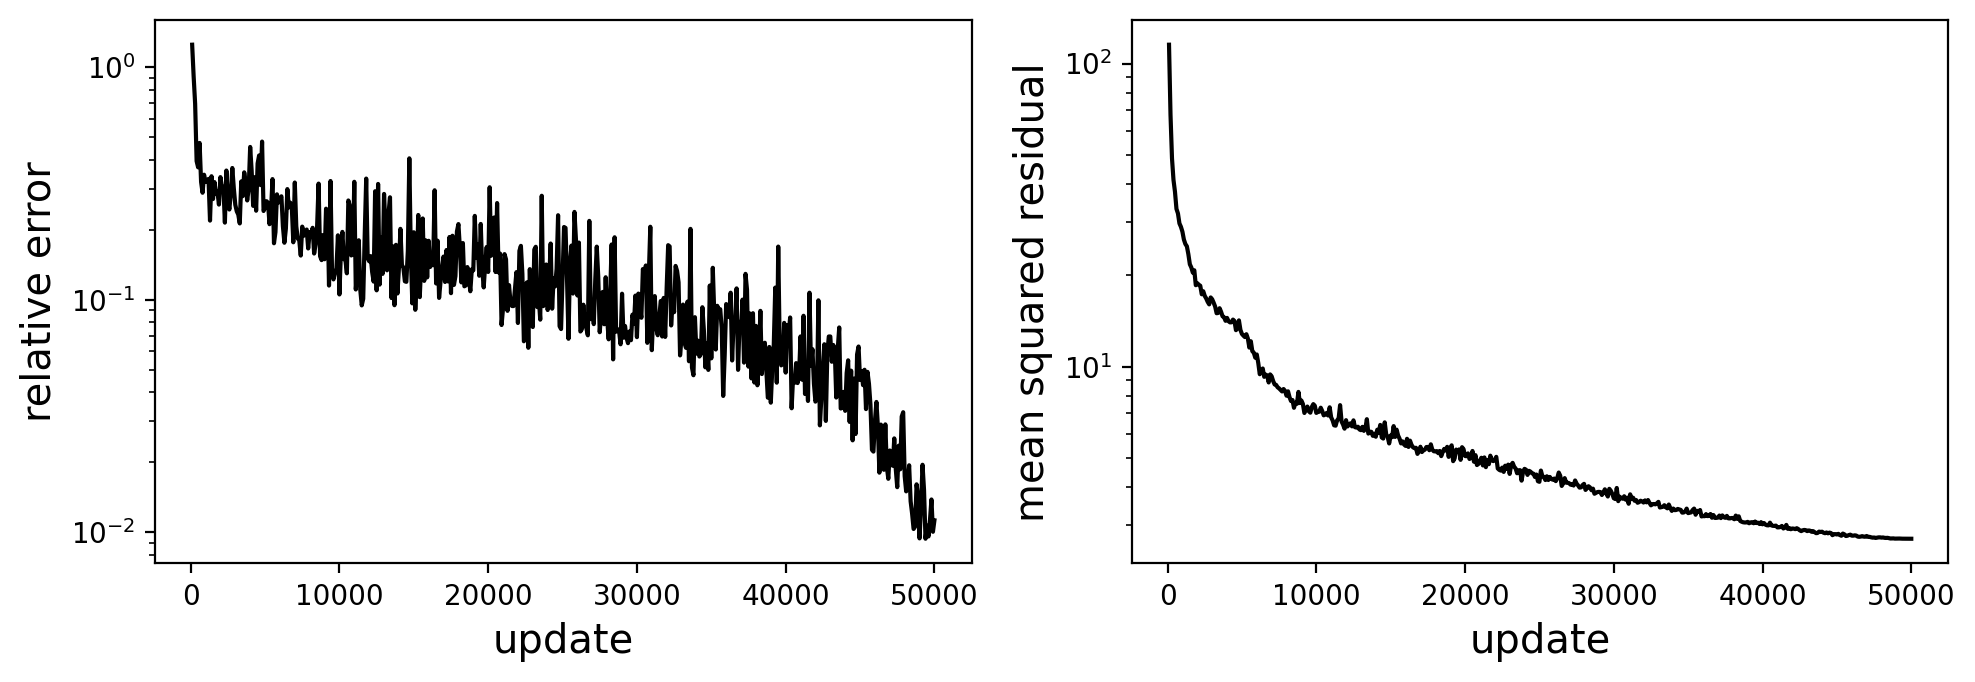

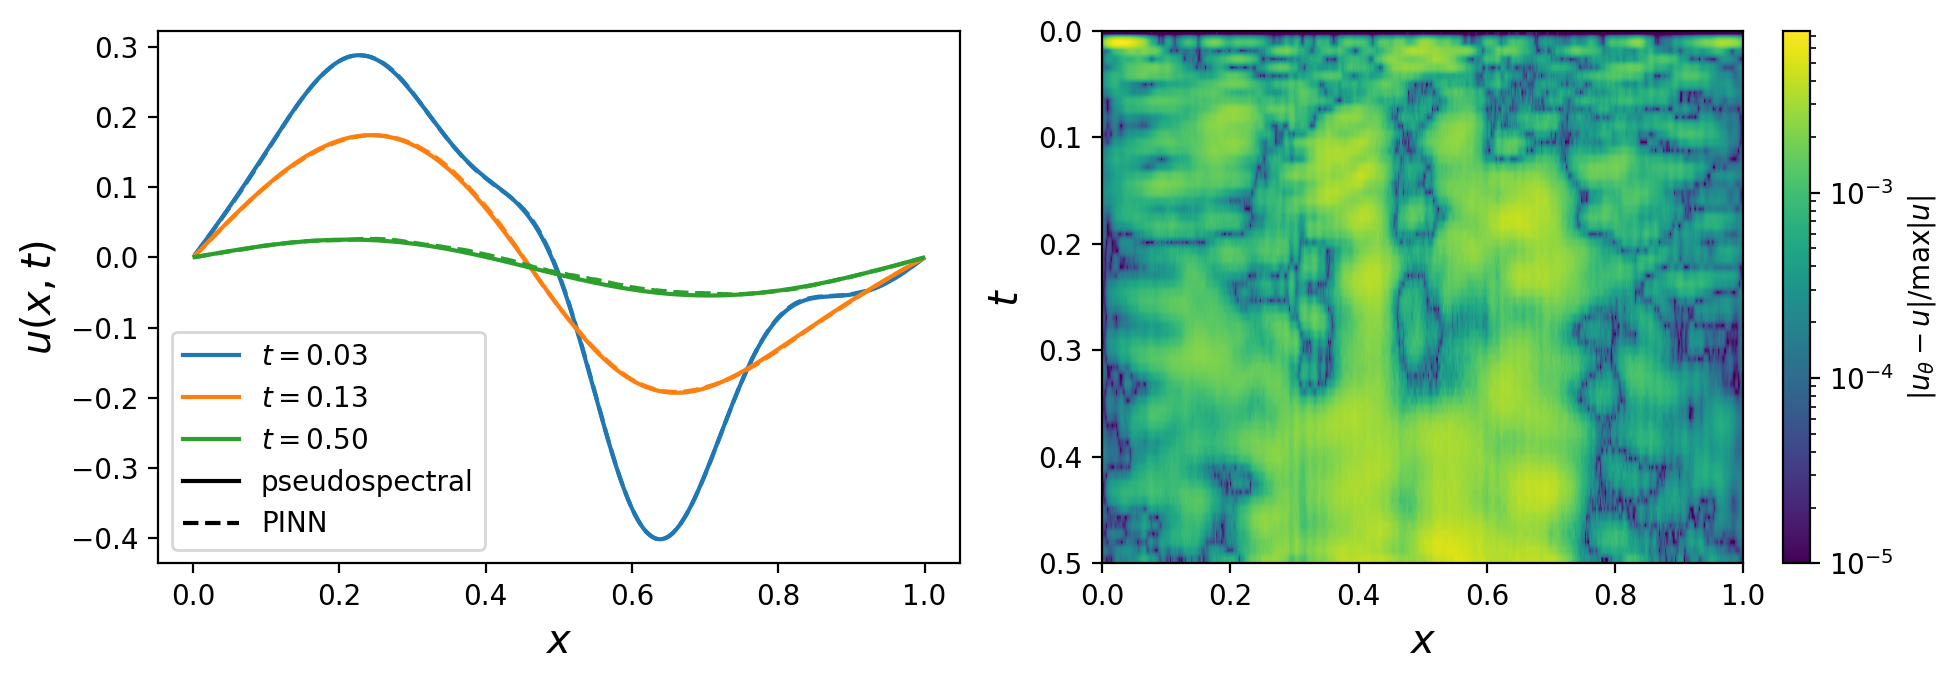

In [9]:
sample = 12
u0 = u0_all[sample]
reference = solve_reference(u0)
model, errors, training_times[sample] = train(u0, reference, random.PRNGKey(45))
plot_results(model, u0, reference, errors)

## Sample 3

The same training procedure with a different initial condition. The network is trained from scratch, since it is specific to the initial condition.

Training time: 17.2 s


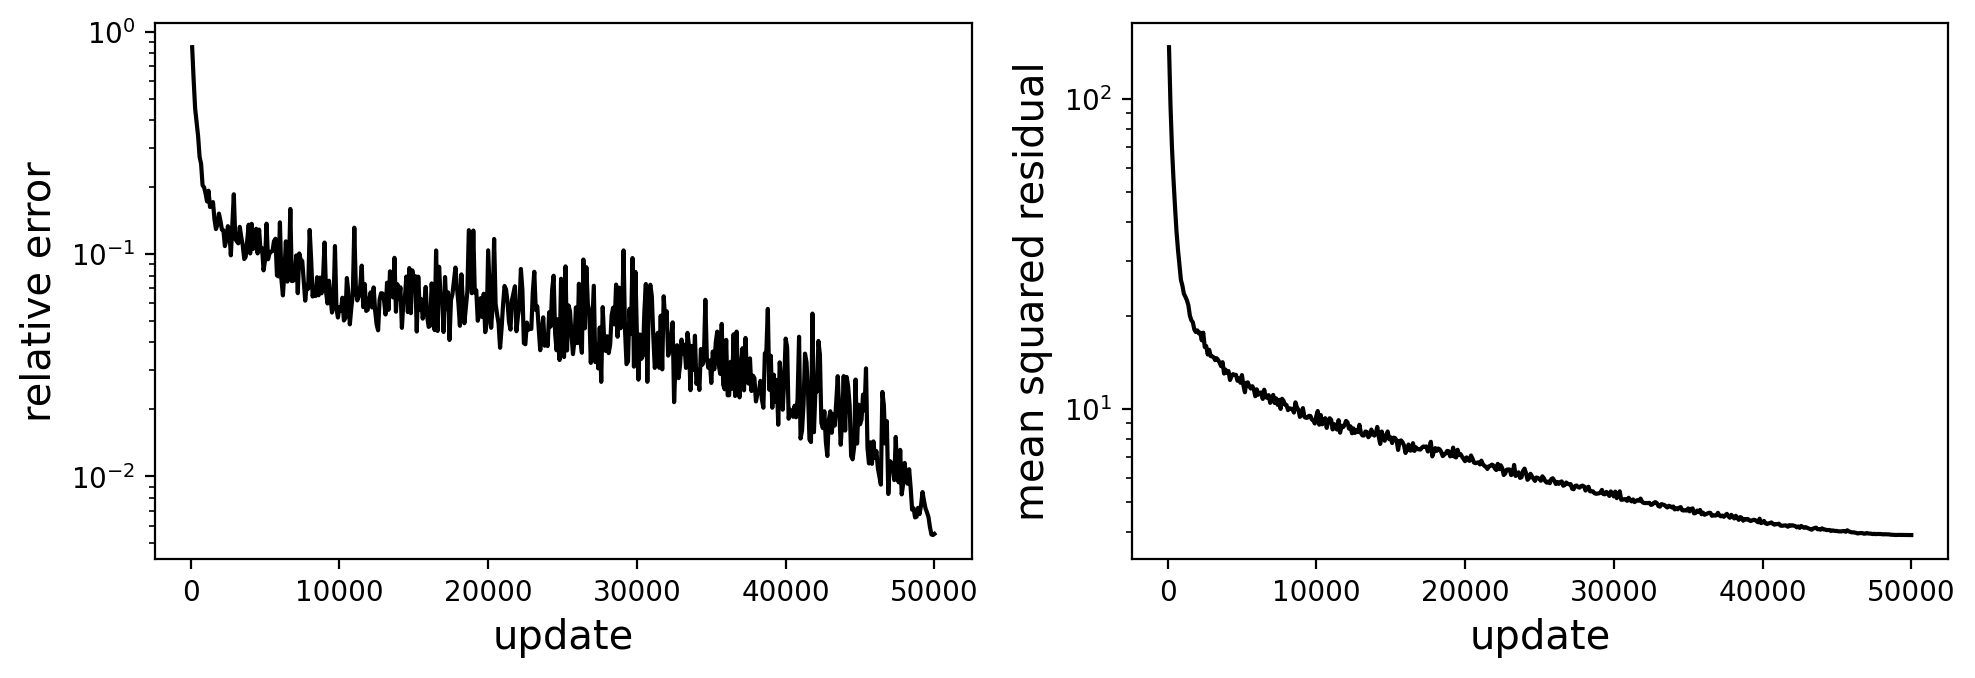

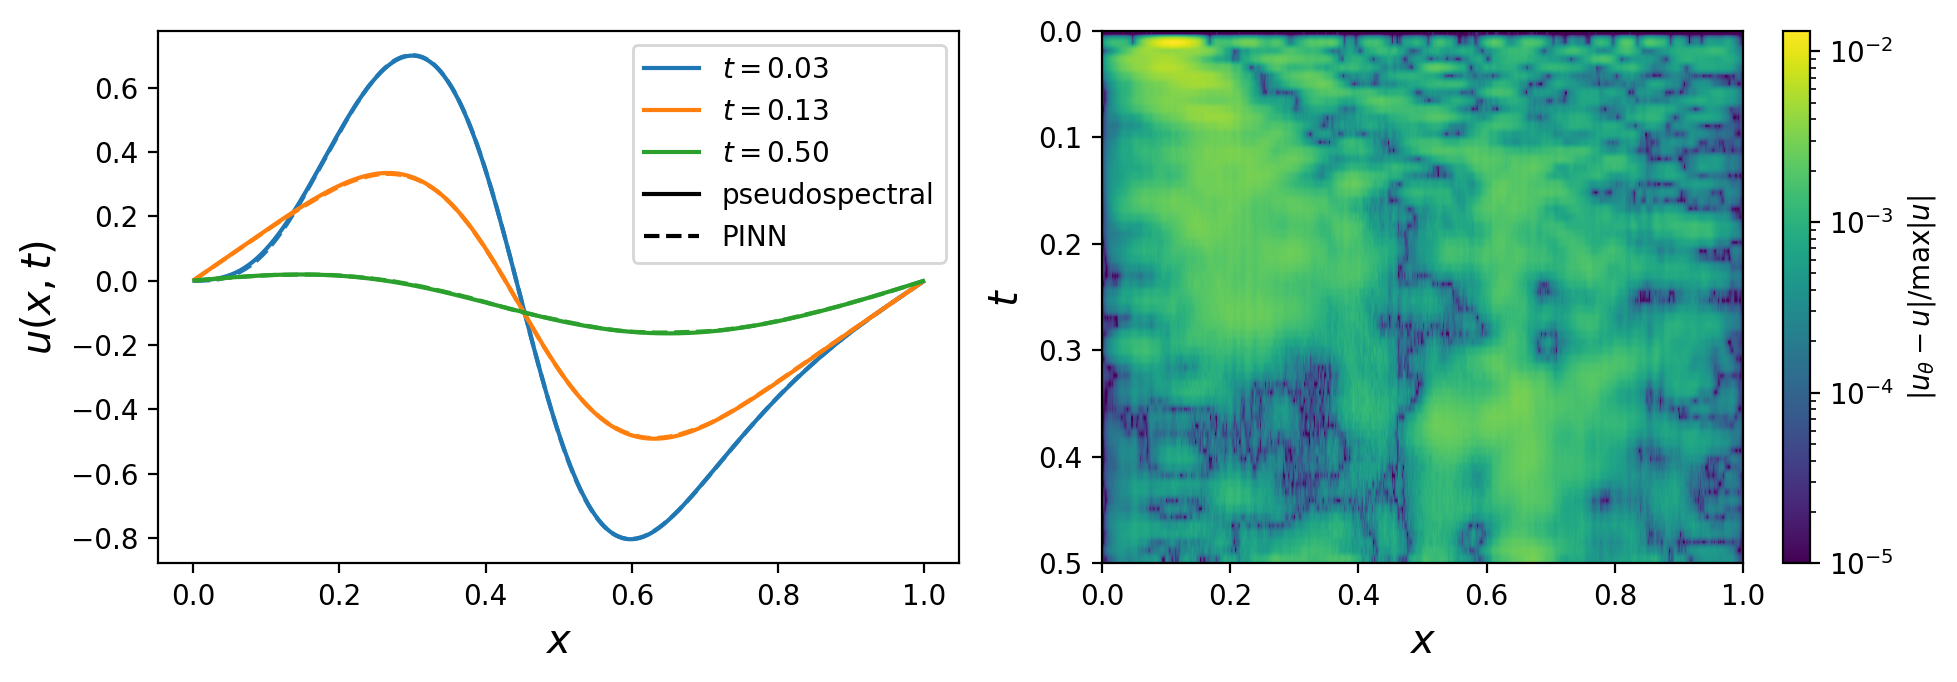

In [10]:
sample = 3
u0 = u0_all[sample]
reference = solve_reference(u0)
model, errors, training_times[sample] = train(u0, reference, random.PRNGKey(45))
plot_results(model, u0, reference, errors)

## Solution time

The times needed to obtain the solution for one initial condition on the whole space-time grid ($64\times512$ values):

- **Pseudospectral solver:** the time of the jitted `solve_reference` (2016 time steps of the integrating factor RK4), measured after a warm-up call. We give it for a single problem and per problem when 100 problems are solved at once with `vmap`.
- **PINN:** the wall-clock time of the training for each of the samples above. It includes the evaluation on the full grid every `N_eval` updates and, for the first sample, the compilation of the training loop.

Both methods run on the same device.

In [11]:
def timeit(fn, *args, n_repeat=100):
    jnp.asarray(fn(*args)).block_until_ready()  # warm-up (compilation)
    start = time.time()
    for _ in range(n_repeat):
        fn(*args).block_until_ready()
    return (time.time() - start) / n_repeat

solver_time = timeit(jit(solve_reference), u0_all[sample])
solver_batch_time = timeit(jit(vmap(solve_reference)), u0_all[:100], n_repeat=10) / 100  # per problem

print("Time per problem")
print(f"  Pseudospectral solver (single solve):          {1e3 * solver_time:10.2f} ms")
print(f"  Pseudospectral solver (100 solves in a batch): {1e3 * solver_batch_time:10.2f} ms")
for s, training_time in training_times.items():
    print(f"  PINN training (sample {s}):{'':<{23 - len(str(s))}}{1e3 * training_time:10.0f} ms")

Time per problem
  Pseudospectral solver (single solve):              265.36 ms
  Pseudospectral solver (100 solves in a batch):       3.11 ms
  PINN training (sample 12):                          24703 ms
  PINN training (sample 3):                           17194 ms
